                       price  buy_vol  sell_vol  micro_OFI  micro_CVD  \
datetime                                                                
2026-06-28 10:00:00  60228.3    0.025     1.036     -1.011     -2.040   
2026-06-28 10:00:01  60236.8    1.648     0.000      1.648     -0.368   
2026-06-28 10:00:02  60238.2    0.661     0.000      0.661      0.053   
2026-06-28 10:00:03  60238.1    0.051     0.057     -0.006      0.049   
2026-06-28 10:00:04  60238.3    0.041     0.000      0.041      0.115   
...                      ...      ...       ...        ...        ...   
2026-07-06 13:26:10  61493.1    0.589     3.334     -2.745      1.094   
2026-07-06 13:26:11  61493.1    0.160     0.002      0.158      1.254   
2026-07-06 13:26:12  61493.1    0.276     0.000      0.276      3.094   
2026-07-06 13:26:13  61487.5    0.005     0.263     -0.258      2.842   
2026-07-06 13:26:14  61494.1    0.640     0.054      0.586      3.907   

                         open      high       low 

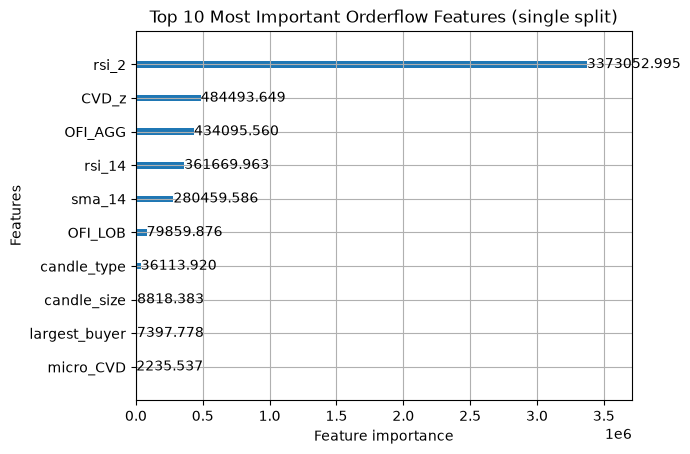


--- Starting 5-Fold Purged & Embargoed Walk-Forward Validation ---
Fold 1 | Train: 32050 (purged 240) | Test: 32290 | Precision: 74.94% | Recall: 79.75%
Fold 2 | Train: 64340 (purged 240) | Test: 32290 | Precision: 0.00% | Recall: 0.00%
Fold 3 | Train: 96630 (purged 240) | Test: 32290 | Precision: 38.46% | Recall: 1.49%
Fold 4 | Train: 128920 (purged 240) | Test: 32290 | Precision: 20.00% | Recall: 95.00%
Fold 5 | Train: 161280 (purged 170) | Test: 32290 | Precision: 0.00% | Recall: 0.00%

--- Fold Stability (Precision / Recall @ 0.5 threshold) ---
Precision: mean=26.68%  std=28.06%
Recall:    mean=35.25%  std=42.84%
High std relative to the mean means the 'edge' is not consistent across time periods —
treat that as a warning sign rather than averaging it away.

--- Feature Importance Stability Across Folds ---
                mean_importance  std_importance
micro_CVD                 424.2      898.456844
buy_vol                   178.4      371.670284
largest_buyer             154.0 

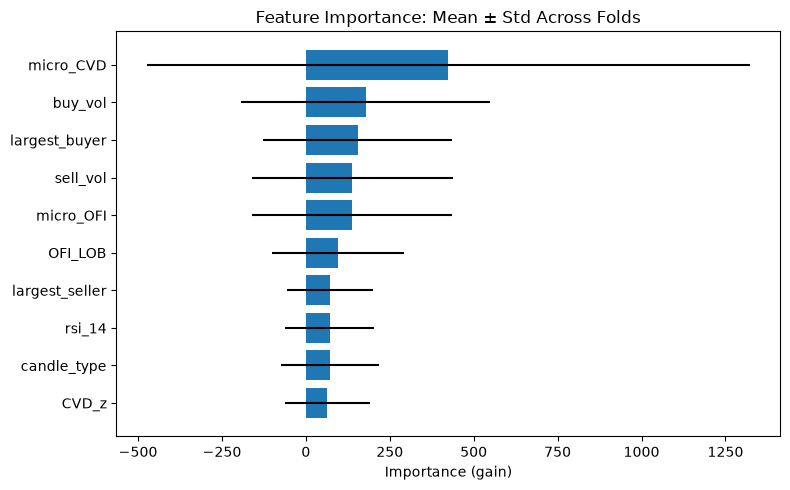


--- Probability Threshold Optimization (Across All Folds) ---
Total out-of-fold samples evaluated: 161450
-----------------------------------------------------------------
Threshold    | Precision    | Total Trades Fired   | Recall
-----------------------------------------------------------------
>=  50.0%   |      63.91% |               1075 | 18.64%
>=  55.0%   |      66.60% |               1009 | 18.23%
>=  60.0%   |      65.38% |                878 | 15.57%
>=  65.0%   |      62.56% |                788 | 13.37%
>=  70.0%   |      63.04% |                782 | 13.37%
>=  75.0%   |      72.64% |                647 | 12.75%
>=  80.0%   |       0.00% |                  0 | 0.00%
>=  85.0%   |       0.00% |                  0 | 0.00%
>=  90.0%   |       0.00% |                  0 | 0.00%
>=  95.0%   |       0.00% |                  0 | 0.00%
-----------------------------------------------------------------


In [1]:
"""
Orderflow "sniper entry" model — fixed pipeline
================================================

Changelog vs. original script:
  1. mid_price no longer subtracts the whole-sample mean (was global lookahead leakage).
  2. Each data file is treated as its own SESSION and run through the entire feature
     pipeline independently, then concatenated with a `session_id` tag. This stops
     resampling/rolling windows from silently blending two possibly-unrelated files.
  3. Barrier is scaled to the label horizon via sqrt(time) scaling of volatility,
     instead of comparing a 1-second return-std to a 240-second move.
  4. Forward-looking labels require a FULL lookahead window (min_periods=lookahead) and
     a non-NaN barrier; rows that don't qualify are dropped, not silently labeled 0.
  5. CVD is detrended (rolling z-score of its slope) instead of used as a raw
     cumulative (non-stationary) feature.
  6. Validation now uses a PURGED + EMBARGOED walk-forward split. Vanilla
     TimeSeriesSplit leaks information because every label looks 240s into the
     future, so rows near a train/test boundary have labels that peek across it.
  7. Added stability reporting: precision/recall mean+std across folds, and
     feature-importance mean+std across folds.
  8. Misc: division-by-zero guards, removed dead/duplicate code, rsi_2 is now
     actually computed (was referenced in a comment but never built).

I could not execute this end-to-end (no access to your CSVs or utils/indicators.py,
utils/engine.py), so it's syntax-checked but not runtime-tested. Run it and send me
the traceback if anything breaks on your data.
"""

import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

import numpy as np
import pandas as pd

from utils.indicators import *
from utils.engine import *

import lightgbm as lgb
from sklearn.metrics import precision_score, recall_score, classification_report
from sklearn.model_selection import TimeSeriesSplit
import matplotlib.pyplot as plt


# ============================================================================
# CONFIG
# ============================================================================
LOOKAHEAD_SECONDS   = 240     # how far forward we check if the barrier was hit
BARRIER_MULTIPLIER  = 1.0     # profit/stop barrier = multiplier * horizon-scaled vol
RSI_FILTER_COLUMN   = 'rsi_14'
RSI_FILTER_THRESHOLD = 30
N_SPLITS            = 5
EMBARGO_SECONDS     = LOOKAHEAD_SECONDS  # buffer after each test fold
EPS                 = 1e-9    # guards against division by zero


# ============================================================================
# STEP 1 — Per-session feature pipeline
# ============================================================================
def load_and_build_state_space(orderbook_path, trades_path, session_id):
    """
    Loads ONE contiguous session's orderbook + trades data and builds the
    1-second state-space feature dataframe. All resampling/rolling happens
    within this session only, so nothing leaks across a file boundary.
    """
    df_orderbook = pd.read_csv(orderbook_path)
    df_trades = pd.read_csv(trades_path)

    df_orderbook['datetime'] = pd.to_datetime(df_orderbook['timestamp'], unit='ms')
    df_trades['datetime'] = pd.to_datetime(df_trades['timestamp'], unit='ms')

    df_orderbook = df_orderbook.set_index('datetime').sort_index()
    df_trades = df_trades.set_index('datetime').sort_index()

    # --- True mid price. (Previously: (bid+ask) - (bid+ask).mean(), which
    # subtracts the FULL SAMPLE mean from every row -> future information
    # leaking into every single timestamp.) ---
    df_orderbook['mid_price'] = (df_orderbook['bid_price'] + df_orderbook['ask_price']) / 2

    df_ob_1m = df_orderbook.resample('1min').agg({
        'mid_price': ['first', 'max', 'min', 'last'],
        'bid_price': 'last',
        'ask_price': 'last',
        'bid_amount': 'sum',
        'ask_amount': 'sum',
    })
    df_ob_1m.columns = ['open', 'high', 'low', 'close', 'bid_price', 'ask_price', 'bid_amount', 'ask_amount']
    df_ob_1m['spread'] = df_ob_1m['ask_price'] - df_ob_1m['bid_price']

    # --- Trades ---
    df_trades['buy_vol'] = df_trades['amount'].where(df_trades['side'] == 'buy', 0)
    df_trades['sell_vol'] = df_trades['amount'].where(df_trades['side'] == 'sell', 0)

    df_micro = df_trades.resample('1s').agg({
        'price': 'last',
        'buy_vol': 'sum',
        'sell_vol': 'sum'
    }).ffill()

    df_micro['micro_OFI'] = df_micro['buy_vol'] - df_micro['sell_vol']
    df_micro['micro_CVD'] = df_micro['micro_OFI'].rolling(10).sum()

    df_trades_1m = df_trades.resample('1min').agg({
        'price': ['first', 'max', 'min', 'last', 'count'],
        'amount': 'sum',
        'buy_vol': ['sum', 'max'],
        'sell_vol': ['sum', 'max']
    })
    df_trades_1m.columns = ['open', 'high', 'low', 'close', 'num_trades', 'volume',
                             'agg_buyer', 'largest_buyer', 'agg_seller', 'largest_seller']
    df_trades_1m = df_trades_1m.dropna(subset=['close'])

    df_price_1m = pd.DataFrame({
        'open': df_ob_1m['open'],
        'high': df_ob_1m['high'],
        'low': df_ob_1m['low'],
        'close': df_ob_1m['close'],
        'largest_buyer': df_trades_1m['largest_buyer'] * 100 / (df_trades_1m['volume'] + EPS),
        'largest_seller': df_trades_1m['largest_seller'] * 100 / (df_trades_1m['volume'] + EPS),
        'OFI_LOB': 100 * (df_ob_1m['bid_amount'] - df_ob_1m['ask_amount']) / (df_ob_1m['bid_amount'] + df_ob_1m['ask_amount'] + EPS),
        'OFI_AGG': 100 * (df_trades_1m['agg_buyer'] - df_trades_1m['agg_seller']) / (df_trades_1m['agg_buyer'] + df_trades_1m['agg_seller'] + EPS),
        'CVD_raw': calculate_cvd(df_trades_1m['agg_buyer'], df_trades_1m['agg_seller']),
        'candle_type': abs(df_ob_1m['close'] - df_ob_1m['open']) / (abs(df_ob_1m['high'] - df_ob_1m['low']) + EPS),
        'candle_size': (df_ob_1m['high'] - df_ob_1m['low']) / ((df_ob_1m['high'] - df_ob_1m['low']).rolling(14).mean() + EPS),
    })

    # CVD is a running cumulative total -> non-stationary, unsafe as a raw ML
    # feature under a chronological split (train/test sit at different "levels").
    # Use a rolling z-score of its change instead.
    cvd_delta = df_price_1m['CVD_raw'].diff()
    df_price_1m['CVD_z'] = (cvd_delta - cvd_delta.rolling(60).mean()) / (cvd_delta.rolling(60).std() + EPS)
    df_price_1m = df_price_1m.drop(columns=['CVD_raw'])

    # --- RSI family (built on price diffs, so output is len(close)-ish, pad front with NaN) ---
    price_clean = np.asarray(df_price_1m['close'], dtype=float)
    diffs = np.diff(price_clean)

    def _pad_front(arr, target_len):
        out = np.full(target_len, np.nan)
        out[-len(arr):] = arr
        return out

    df_price_1m['rsi_2'] = _pad_front(get_wilders_rsi(diffs, 2), len(df_price_1m))
    rsi_14_raw = get_wilders_rsi(diffs, 14)
    df_price_1m['rsi_14'] = _pad_front(rsi_14_raw, len(df_price_1m))
    df_price_1m['sma_14'] = _pad_front(sma(rsi_14_raw, 14), len(df_price_1m))

    # Shift macro (1m) features by 1 bar so a 1s row only ever sees the LAST
    # *closed* candle's features, never the one currently forming.
    df_macro_shifted = df_price_1m.shift(1)

    df_state_space = df_micro.join(df_macro_shifted, how='left').ffill()
    df_state_space = df_state_space.dropna()
    df_state_space['session_id'] = session_id

    return df_state_space


# ============================================================================
# STEP 2 — Build combined state space from all sessions
# ============================================================================
session_0 = load_and_build_state_space(
    "./csv/BTCUSDT_orderbook.csv", "./csv/BTCUSDT_trades.csv", session_id=0
)
session_1 = load_and_build_state_space(
    "./csv/BTCUSDT_orderbook_2.csv", "./csv/BTCUSDT_trades_2.csv", session_id=1
)

df_state_space = pd.concat([session_0, session_1]).sort_index()
print(df_state_space)


# ============================================================================
# STEP 3 — Barrier labeling (per session, so the forward window never crosses
# a file boundary; also never silently defaults an unlabelable row to 0)
# ============================================================================
def add_barrier_labels(df, lookahead_seconds=LOOKAHEAD_SECONDS, barrier_mult=BARRIER_MULTIPLIER):
    labeled = []

    for _, g in df.groupby('session_id', sort=False):
        g = g.copy()

        # Volatility of 1-second returns, scaled up to the label horizon (~sqrt(t)).
        ret_std_1s = g['price'].pct_change().rolling(window=100).std()
        horizon_std = ret_std_1s * np.sqrt(lookahead_seconds)

        g['profit_barrier'] = horizon_std * barrier_mult
        g['stop_barrier'] = horizon_std * barrier_mult

        # Forward max/min over the FULL lookahead window only. min_periods
        # forces incomplete tail rows to NaN instead of using a truncated window.
        forward_max = (g['price'].iloc[::-1]
                       .rolling(window=lookahead_seconds, min_periods=lookahead_seconds)
                       .max().iloc[::-1])
        forward_min = (g['price'].iloc[::-1]
                       .rolling(window=lookahead_seconds, min_periods=lookahead_seconds)
                       .min().iloc[::-1])

        mfe = (forward_max - g['price']) / g['price']
        mae = (g['price'] - forward_min) / g['price']

        valid = g['profit_barrier'].notna() & forward_max.notna() & forward_min.notna()

        g['target'] = np.nan
        g.loc[valid, 'target'] = np.where(
            (mfe[valid] >= g.loc[valid, 'profit_barrier']) & (mae[valid] < g.loc[valid, 'stop_barrier']),
            1, 0
        )

        labeled.append(g)

    out = pd.concat(labeled)
    out = out.dropna(subset=['target'])   # drop rows with no complete forward window / no vol history
    out['target'] = out['target'].astype(int)
    return out


df_state_space = add_barrier_labels(df_state_space)

# Filter to the "hunting zone" — model only needs to learn entries inside this regime.
df_training_zone = df_state_space[df_state_space[RSI_FILTER_COLUMN] < RSI_FILTER_THRESHOLD]
print(f"Training zone size: {len(df_training_zone)}")


# ============================================================================
# STEP 4 — Features / target
# ============================================================================
drop_cols = ['target', 'price', 'open', 'high', 'low', 'close',
             'profit_barrier', 'stop_barrier', 'session_id']
features = [c for c in df_training_zone.columns if c not in drop_cols]

X = df_training_zone[features]
y = df_training_zone['target']

print(f"Training on features: {features}")


# ============================================================================
# STEP 5 — Quick sanity check: single purged 80/20 chronological split
# ============================================================================
split_idx = int(len(X) * 0.8)
cutoff_time = X.index[split_idx]

# Purge: drop any training row whose label window could overlap the test period.
purge_mask = X.index + pd.Timedelta(seconds=LOOKAHEAD_SECONDS) < cutoff_time

X_train, X_test = X[purge_mask], X.iloc[split_idx:]
y_train, y_test = y[purge_mask], y.iloc[split_idx:]

print(f"[Sanity check] Train size: {len(X_train)} | Test size: {len(X_test)}")

neg_pos_ratio = sum(y_train == 0) / max(sum(y_train == 1), 1)
print(f"[Sanity check] Negative to Positive class ratio: {neg_pos_ratio:.2f}")

clf_sanity = lgb.LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    num_leaves=31,
    scale_pos_weight=neg_pos_ratio,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

clf_sanity.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
)

y_pred_sanity = clf_sanity.predict(X_test)
print("\n--- Sanity Check Evaluation (single purged split) ---")
print(classification_report(y_test, y_pred_sanity, zero_division=0))
print(f"Sniper Precision: {precision_score(y_test, y_pred_sanity, zero_division=0):.2%}")

lgb.plot_importance(clf_sanity, max_num_features=10, importance_type='gain')
plt.title("Top 10 Most Important Orderflow Features (single split)")
plt.show()


# ============================================================================
# STEP 6 — Purged + Embargoed walk-forward validation (the real stability test)
# ============================================================================
def purged_walk_forward_splits(index, n_splits, embargo_seconds, label_horizon_seconds):
    """
    Like TimeSeriesSplit, but:
      1. PURGE: drops training rows whose forward label window [t, t+horizon]
         would overlap the test fold (prevents the label from leaking future
         test-period information into training).
      2. EMBARGO: also drops training rows in a buffer immediately AFTER the
         test fold, since TimeSeriesSplit folds are cumulative and that data
         would otherwise become training data in a later split iteration.

    `index` must be the (already time-sorted) DatetimeIndex of X/y.
    Yields (train_idx, test_idx, n_purged) as positional index arrays.
    """
    n = len(index)
    base_splitter = TimeSeriesSplit(n_splits=n_splits)
    embargo = pd.Timedelta(seconds=embargo_seconds)
    horizon = pd.Timedelta(seconds=label_horizon_seconds)

    for train_idx, test_idx in base_splitter.split(np.arange(n)):
        test_start_time = index[test_idx[0]]
        test_end_time = index[test_idx[-1]]
        train_times = index[train_idx]

        purge_mask = train_times + horizon < test_start_time
        embargo_mask = ~((train_times > test_end_time) & (train_times <= test_end_time + embargo))

        keep_mask = purge_mask & embargo_mask
        purged_train_idx = train_idx[keep_mask]
        n_purged = len(train_idx) - len(purged_train_idx)

        yield purged_train_idx, test_idx, n_purged


n_splits = N_SPLITS
splitter = purged_walk_forward_splits(
    X.index, n_splits=n_splits,
    embargo_seconds=EMBARGO_SECONDS,
    label_horizon_seconds=LOOKAHEAD_SECONDS
)

all_true_labels = []
all_pred_probas = []
fold_precisions = []
fold_recalls = []
fold_importances = []

print(f"\n--- Starting {n_splits}-Fold Purged & Embargoed Walk-Forward Validation ---")

for fold, (train_idx, test_idx, n_purged) in enumerate(splitter, start=1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    if len(X_train) == 0 or y_train.nunique() < 2:
        print(f"Fold {fold} | skipped — not enough training data/classes left after purging")
        continue

    neg_pos_ratio = sum(y_train == 0) / max(sum(y_train == 1), 1)

    clf = lgb.LGBMClassifier(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=5,
        num_leaves=31,
        scale_pos_weight=neg_pos_ratio,
        random_state=42,
        n_jobs=-1,
        verbose=-1
    )

    clf.fit(
        X_train, y_train,
        eval_set=[(X_test, y_test)],
        callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
    )

    y_proba = clf.predict_proba(X_test)[:, 1]
    fold_preds = (y_proba >= 0.5).astype(int)
    fold_precision = precision_score(y_test, fold_preds, zero_division=0)
    fold_recall = recall_score(y_test, fold_preds, zero_division=0)

    print(f"Fold {fold} | Train: {len(X_train)} (purged {n_purged}) | Test: {len(X_test)} "
          f"| Precision: {fold_precision:.2%} | Recall: {fold_recall:.2%}")

    all_true_labels.extend(y_test.values)
    all_pred_probas.extend(y_proba)
    fold_precisions.append(fold_precision)
    fold_recalls.append(fold_recall)
    fold_importances.append(clf.feature_importances_)

all_true_labels = np.array(all_true_labels)
all_pred_probas = np.array(all_pred_probas)


# ---- Stability summary #1: precision/recall consistency across folds ----
print("\n--- Fold Stability (Precision / Recall @ 0.5 threshold) ---")
print(f"Precision: mean={np.mean(fold_precisions):.2%}  std={np.std(fold_precisions):.2%}")
print(f"Recall:    mean={np.mean(fold_recalls):.2%}  std={np.std(fold_recalls):.2%}")
print("High std relative to the mean means the 'edge' is not consistent across time periods —")
print("treat that as a warning sign rather than averaging it away.")

# ---- Stability summary #2: feature importance consistency across folds ----
if fold_importances:
    imp_df = pd.DataFrame(fold_importances, columns=features)
    imp_summary = pd.DataFrame({
        'mean_importance': imp_df.mean(),
        'std_importance': imp_df.std()
    }).sort_values('mean_importance', ascending=False)

    print("\n--- Feature Importance Stability Across Folds ---")
    print(imp_summary)

    top_n = imp_summary.head(10)
    plt.figure(figsize=(8, 5))
    plt.barh(top_n.index[::-1], top_n['mean_importance'][::-1],
             xerr=top_n['std_importance'][::-1])
    plt.title("Feature Importance: Mean ± Std Across Folds")
    plt.xlabel("Importance (gain)")
    plt.tight_layout()
    plt.show()


# ---- Threshold sweep across all out-of-fold predictions ----
print("\n--- Probability Threshold Optimization (Across All Folds) ---")
print(f"Total out-of-fold samples evaluated: {len(all_true_labels)}")
print("-" * 65)
print(f"{'Threshold':<12} | {'Precision':<12} | {'Total Trades Fired':<20} | {'Recall'}")
print("-" * 65)

thresholds = np.arange(0.50, 0.96, 0.05)
for t in thresholds:
    custom_preds = (all_pred_probas >= t).astype(int)
    prec = precision_score(all_true_labels, custom_preds, zero_division=0)
    rec = recall_score(all_true_labels, custom_preds, zero_division=0)
    total_trades = int(custom_preds.sum())
    print(f">= {t*100:>5.1f}%   | {prec:>11.2%} | {total_trades:>18} | {rec:.2%}")

print("-" * 65)